# Explainable Cyber Threat Defense Workbench

## Open-world network-flow triage under a fixed review budget

**Research question:** Can a flow-based triage workflow surface attack categories it never saw during training, while keeping benign traffic within a bounded analyst review queue?

This MVP separates two questions: **known attack risk** (a supervised model trained on normal traffic and observed attack categories) and **novel behavior** (an Isolation Forest trained only on normal traffic). It compares a known-risk queue, a novelty queue, and a small two-lane policy at the same review budget. The main experiment holds out one `attack_cat` category from model development at a time.

“Unseen” here means **an attack category withheld from the training data**. It is a controlled proxy for unknown attacks, not evidence of zero-day detection. The dataset has no timestamps, so this experiment cannot test future-period drift. Its purpose is a transparent research benchmark, not a live SOC system.

## 1. Load the dataset and record provenance

Place the published UNSW-NB15 training and testing CSVs in `data/raw/`. The `attack_cat` column is used only to define held-out-category evaluation folds and report results; it is never a model feature. `label` is the binary outcome. `id` is excluded.

In [1]:
from pathlib import Path
import hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.ensemble import IsolationForest
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import average_precision_score, roc_auc_score, brier_score_loss
from sklearn.metrics import precision_score, recall_score, confusion_matrix
from xgboost import XGBClassifier, DMatrix

SEED = 42
ROOT = Path.cwd()
TRAIN_PATH = ROOT / 'data/raw/UNSW_NB15_training-set.csv'
TEST_PATH = ROOT / 'data/raw/UNSW_NB15_testing-set.csv'
for path in [TRAIN_PATH, TEST_PATH]:
    if not path.exists():
        raise FileNotFoundError(f'Missing {path}. Follow the README data instructions.')

def sha256(path):
    digest = hashlib.sha256()
    with path.open('rb') as handle:
        for chunk in iter(lambda: handle.read(1024 * 1024), b''):
            digest.update(chunk)
    return digest.hexdigest()

train_all = pd.read_csv(TRAIN_PATH)
test_all = pd.read_csv(TEST_PATH)
display(pd.DataFrame([
    {'file': TRAIN_PATH.name, 'rows': len(train_all), 'sha256': sha256(TRAIN_PATH)},
    {'file': TEST_PATH.name, 'rows': len(test_all), 'sha256': sha256(TEST_PATH)},
]))
print('Training columns:', len(train_all.columns), '| Test columns:', len(test_all.columns))

,file,rows,sha256
0,UNSW_NB15_training-set.csv,175341,bec7dd5ec88dc2a0ccc7a07879d338395ed7421750f675...
1,UNSW_NB15_testing-set.csv,82332,734fe6642edf758f7c94d7d9149426b49d202fe8e7bf0b...


Training columns: 45 | Test columns: 45


## 2. Inspect attack categories and support

A leave-one-category-out experiment is only interpretable if we show how many examples each category contributes. Sparse categories will have noisier recall estimates.

,split,flows,attack_labeled,attack_rate,missing_cells
0,published train,175341,119341,0.680622,0
1,published test,82332,45332,0.550600,0


,train_attack_flows,test_attack_flows
attack_cat,,
Analysis,2000,677
Backdoor,1746,583
DoS,12264,4089
Exploits,33393,11132
Fuzzers,18184,6062
Generic,40000,18871
Reconnaissance,10491,3496
Shellcode,1133,378
Worms,130,44


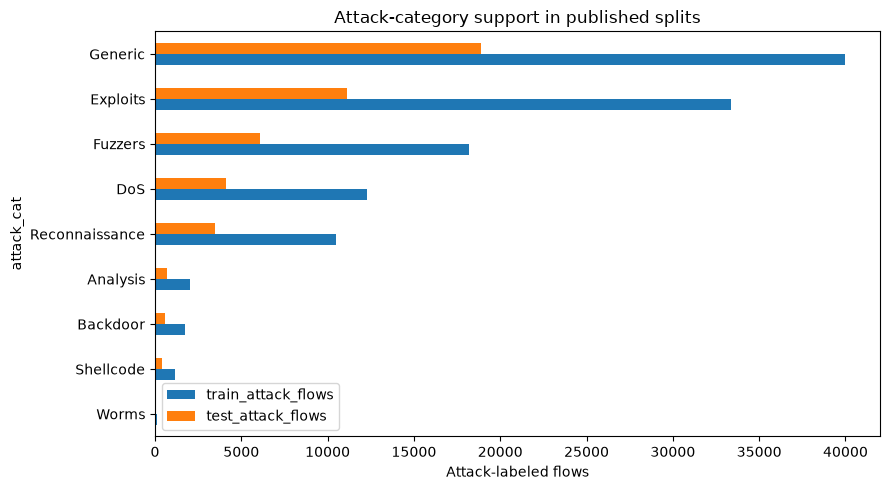

In [2]:
profile = pd.DataFrame({
    'split': ['published train', 'published test'],
    'flows': [len(train_all), len(test_all)],
    'attack_labeled': [int(train_all.label.sum()), int(test_all.label.sum())],
    'attack_rate': [train_all.label.mean(), test_all.label.mean()],
    'missing_cells': [int(train_all.isna().sum().sum()), int(test_all.isna().sum().sum())],
})
display(profile)
category_counts = pd.concat([
    train_all.loc[train_all.label.eq(1), 'attack_cat'].value_counts().rename('train_attack_flows'),
    test_all.loc[test_all.label.eq(1), 'attack_cat'].value_counts().rename('test_attack_flows'),
], axis=1).fillna(0).astype(int)
display(category_counts.sort_index())
ax = category_counts.sort_values('train_attack_flows').plot(
    kind='barh', figsize=(9, 5), title='Attack-category support in published splits')
ax.set_xlabel('Attack-labeled flows')
plt.tight_layout()
plt.show()

## 3. Remove exact train/test input overlap

Repeated feature rows occur in the published files. We hash every input column except `id`, `label`, and `attack_cat`. The primary test population excludes any row whose input fingerprint appears anywhere in the published training split. This conservative filter prevents an exact copy of a held-out-category flow from crossing the published boundary; it does not remove all correlations among flows.

In [3]:
INPUT_COLUMNS = [c for c in train_all.columns if c not in {'id', 'attack_cat', 'label'}]
train_hash = pd.util.hash_pandas_object(train_all[INPUT_COLUMNS], index=False)
test_hash = pd.util.hash_pandas_object(test_all[INPUT_COLUMNS], index=False)
train_hash_set = set(train_hash.to_numpy())
test_overlap = test_hash.isin(train_hash_set)
test = test_all.loc[~test_overlap].reset_index(drop=True)
test_hash_primary = test_hash.loc[~test_overlap].reset_index(drop=True)

overlap_audit = pd.DataFrame({
    'measure': ['published train rows', 'published test rows',
                'test rows with exact input match in train', 'primary test rows retained',
                'duplicate train rows', 'duplicate test rows'],
    'count': [len(train_all), len(test_all), int(test_overlap.sum()), len(test),
              int(train_hash.duplicated().sum()), int(test_hash.duplicated().sum())],
})
display(overlap_audit)
print(f'Primary test attack-label share: {test.label.mean():.1%}')

,measure,count
0,published train rows,175341
1,published test rows,82332
2,test rows with exact input match in train,8541
3,primary test rows retained,73791
4,duplicate train rows,74301
5,duplicate test rows,28386


Primary test attack-label share: 51.9%


## 4. Define the features and the open-world protocol

The model sees 17 numeric flow/count fields and three categorical fields. It does **not** see `id`, `label`, or `attack_cat`.

For each fold, one attack category is treated as unknown:

1. Remove that category's training rows **and any training rows with identical input fingerprints**.
2. Fit the known-risk classifier on the remaining normal and attack flows.
3. Fit the Isolation Forest on the remaining normal flows only.
4. Score the unchanged primary test set and rank alerts using scores alone.

The test `attack_cat` is read only after queue selection to score the held-out-category experiment. The attack categories are not threat families in a complete operational taxonomy; they are benchmark labels used to create controlled holdouts.

In [4]:
BASE_NUMERIC = [
    'dur', 'spkts', 'dpkts', 'sbytes', 'dbytes', 'rate', 'sttl', 'dttl',
    'sload', 'dload', 'sloss', 'dloss', 'ct_srv_src', 'ct_dst_ltm',
    'ct_src_dport_ltm', 'ct_dst_sport_ltm', 'ct_dst_src_ltm',
]
CATEGORICAL = ['proto', 'service', 'state']
FEATURES = BASE_NUMERIC + CATEGORICAL
ANOMALY_FEATURES = ['dur', 'spkts', 'dpkts', 'sbytes', 'dbytes', 'rate', 'sload', 'dload']
assert set(FEATURES).issubset(INPUT_COLUMNS)
assert train_all[BASE_NUMERIC].ge(0).all().all()
attack_categories = sorted(train_all.loc[train_all.label.eq(1), 'attack_cat'].dropna().unique())
assert set(attack_categories).issubset(set(test.attack_cat.dropna().unique()))

test_category_support = test.loc[test.label.eq(1), 'attack_cat'].value_counts()
category_plan = pd.DataFrame({
    'attack_category_held_out': attack_categories,
    'train_support_before_holdout': [int((train_all.attack_cat.eq(cat) & train_all.label.eq(1)).sum()) for cat in attack_categories],
    'primary_test_support': [int(test_category_support.get(cat, 0)) for cat in attack_categories],
})
display(category_plan)
print('Numeric inputs:', len(BASE_NUMERIC), '| categorical inputs:', len(CATEGORICAL))

,attack_category_held_out,train_support_before_holdout,primary_test_support
0,Analysis,2000,552
1,Backdoor,1746,579
2,DoS,12264,2085
3,Exploits,33393,9330
4,Fuzzers,18184,5801
5,Generic,40000,17149
6,Reconnaissance,10491,2358
7,Shellcode,1133,365
8,Worms,130,44


Numeric inputs: 17 | categorical inputs: 3


## 5. Set a fixed review budget and two-lane policy

The primary review budget is **10% of primary-test flows**. We compare three policies at exactly that queue size:

- **Known-risk only:** all slots go to the supervised XGBoost score.
- **Novelty only:** all slots go to the Isolation Forest score.
- **Two-lane 75/25:** 75% of slots go to known-risk ranking; the remaining 25% go to the highest-novelty flows not already selected.

The 75/25 allocation is a transparent starting policy, not a tuned optimum. We also report 5% and 20% total budgets. No test labels are used to choose model scores, categories, or queue members.

In [5]:
PRIMARY_BUDGET = 0.10
BUDGET_RATES = [0.05, 0.10, 0.20]
KNOWN_RISK_SHARE = 0.75


def make_preprocessor():
    return ColumnTransformer([
        ('numeric', Pipeline([
            ('log', FunctionTransformer(np.log1p, feature_names_out='one-to-one')),
            ('scale', StandardScaler(with_mean=False)),
        ]), BASE_NUMERIC),
        ('categorical', OneHotEncoder(handle_unknown='ignore'), CATEGORICAL),
    ])


def make_known_model():
    # Fixed settings from the prior benchmark; no test-based tuning.
    return XGBClassifier(
        n_estimators=140, max_depth=3, learning_rate=0.08,
        subsample=0.85, colsample_bytree=0.85,
        tree_method='hist', n_jobs=4, eval_metric='logloss', random_state=SEED,
    )


def top_n_mask(scores, count):
    scores = np.asarray(scores)
    count = min(max(int(count), 0), len(scores))
    chosen = np.zeros(len(scores), dtype=bool)
    if count:
        chosen[np.argsort(-scores, kind='stable')[:count]] = True
    return chosen


def make_two_lane_queue(known_scores, novelty_scores, budget, known_share=KNOWN_RISK_SHARE):
    known_count = int(round(budget * known_share))
    known_lane = top_n_mask(known_scores, known_count)
    novelty_count = budget - int(known_lane.sum())
    novelty_pool = np.flatnonzero(~known_lane)
    novelty_local = top_n_mask(np.asarray(novelty_scores)[novelty_pool], novelty_count)
    novelty_lane = np.zeros(len(known_scores), dtype=bool)
    novelty_lane[novelty_pool[novelty_local]] = True
    queue = known_lane | novelty_lane
    assert int(queue.sum()) == budget
    return queue, known_lane, novelty_lane


print(f'Primary budget: {PRIMARY_BUDGET:.0%}; two-lane split: {KNOWN_RISK_SHARE:.0%} known-risk / {1-KNOWN_RISK_SHARE:.0%} novelty')

Primary budget: 10%; two-lane split: 75% known-risk / 25% novelty


## 6. Run leave-one-attack-category-out folds

The Isolation Forest is a **novelty ranking score**, not a probability that a flow is malicious. It is fit only on normal training rows. The known-risk classifier uses ordinary binary labels from the attack categories that remain in that fold.

We also remove training examples whose exact feature fingerprints appear in the withheld category. This guards against a duplicate flow being presented to the model under a different category label.

In [6]:
def alert_metrics(y_true, alert_mask):
    y_true = np.asarray(y_true, dtype=int)
    alert_mask = np.asarray(alert_mask, dtype=bool)
    tn, fp, fn, tp = confusion_matrix(y_true, alert_mask, labels=[0, 1]).ravel()
    return {
        'alerts': int(alert_mask.sum()),
        'attack_alerts': int(tp),
        'normal_alerts': int(fp),
        'precision': precision_score(y_true, alert_mask, zero_division=0),
        'overall_attack_recall': recall_score(y_true, alert_mask, zero_division=0),
        'normal_alerts_per_1000': 1000 * fp / (fp + tn) if fp + tn else np.nan,
    }


def score_fold(heldout_category):
    heldout_mask = train_all.label.eq(1) & train_all.attack_cat.eq(heldout_category)
    heldout_hashes = set(train_hash.loc[heldout_mask].to_numpy())
    eligible_mask = ~train_hash.isin(heldout_hashes)
    fold_train = train_all.loc[eligible_mask].copy()
    assert not (fold_train.label.eq(1) & fold_train.attack_cat.eq(heldout_category)).any()

    preprocessor = make_preprocessor()
    X_train = preprocessor.fit_transform(fold_train[FEATURES])
    model = make_known_model()
    model.fit(X_train, fold_train.label.astype(int))
    X_test = preprocessor.transform(test[FEATURES])
    known_scores = model.predict_proba(X_test)[:, 1]

    normal_train = fold_train.loc[fold_train.label.eq(0), ANOMALY_FEATURES]
    isolation = IsolationForest(
        n_estimators=100, max_samples=4096, n_jobs=4, random_state=SEED,
    )
    isolation.fit(np.log1p(normal_train))
    novelty_scores = -isolation.score_samples(np.log1p(test[ANOMALY_FEATURES]))

    y = test.label.to_numpy(dtype=int)
    categories = test.attack_cat.to_numpy()
    heldout_rows = (y == 1) & (categories == heldout_category)
    known_attack_rows = (y == 1) & (categories != heldout_category)
    rows = []
    for budget_rate in BUDGET_RATES:
        budget = max(1, int(round(len(test) * budget_rate)))
        policies = {
            'Known-risk only': (top_n_mask(known_scores, budget),
                                top_n_mask(known_scores, budget), np.zeros(len(test), dtype=bool)),
            'Novelty only': (top_n_mask(novelty_scores, budget),
                             np.zeros(len(test), dtype=bool), top_n_mask(novelty_scores, budget)),
        }
        hybrid, known_lane, novelty_lane = make_two_lane_queue(
            known_scores, novelty_scores, budget, KNOWN_RISK_SHARE)
        policies['Two-lane 75/25'] = (hybrid, known_lane, novelty_lane)

        for policy, (queue, known_part, novelty_part) in policies.items():
            metrics = alert_metrics(y, queue)
            novelty_count = int(novelty_part.sum())
            unknown_hits = int((novelty_part & heldout_rows).sum())
            rows.append({
                'heldout_category': heldout_category,
                'heldout_test_support': int(heldout_rows.sum()),
                'training_rows_removed_for_holdout_and_exact_aliases': int((~eligible_mask).sum()),
                'budget_rate': budget_rate,
                'budget_flows': budget,
                'policy': policy,
                **metrics,
                'heldout_category_recall': int((queue & heldout_rows).sum()) / max(int(heldout_rows.sum()), 1),
                'known_category_recall': int((queue & known_attack_rows).sum()) / max(int(known_attack_rows.sum()), 1),
                'novelty_lane_flows': novelty_count,
                'heldout_hits_in_novelty_lane': unknown_hits,
                'heldout_precision_in_novelty_lane': unknown_hits / novelty_count if novelty_count else np.nan,
            })

    artifact = {
        'preprocessor': preprocessor,
        'known_model': model,
        'isolation_forest': isolation,
        'normal_reference': normal_train.copy(),
        'heldout_hashes': heldout_hashes,
        'train_rows': len(fold_train),
    }
    return pd.DataFrame(rows), artifact


fold_results = []
focus_category = 'Exploits' if 'Exploits' in attack_categories else attack_categories[0]
focus_artifact = None
for position, category in enumerate(attack_categories, start=1):
    print(f'Fold {position}/{len(attack_categories)}: holding out {category}')
    fold_table, artifact = score_fold(category)
    fold_results.append(fold_table)
    if category == focus_category:
        focus_artifact = artifact

results = pd.concat(fold_results, ignore_index=True)
print('Completed category folds:', results.heldout_category.nunique())
print('Primary test flows scored per fold:', len(test))

Fold 1/9: holding out Analysis
Fold 2/9: holding out Backdoor
Fold 3/9: holding out DoS
Fold 4/9: holding out Exploits
Fold 5/9: holding out Fuzzers
Fold 6/9: holding out Generic
Fold 7/9: holding out Reconnaissance
Fold 8/9: holding out Shellcode
Fold 9/9: holding out Worms
Completed category folds: 9
Primary test flows scored per fold: 73791


## 7. Compare the same-budget queues

For every held-out category and budget, the three policies alert exactly the same number of test rows. The headline metric is held-out-category recall at the 10% budget, alongside benign alerts per 1,000 normal-labeled flows and overall precision. The novelty lane is also measured separately to show whether it finds the held-out category.

In [7]:
primary = results.loc[results.budget_rate.eq(PRIMARY_BUDGET)].copy()
per_category = primary[[
    'heldout_category', 'heldout_test_support', 'policy', 'alerts', 'precision',
    'overall_attack_recall', 'heldout_category_recall', 'known_category_recall',
    'normal_alerts_per_1000', 'novelty_lane_flows', 'heldout_hits_in_novelty_lane',
    'heldout_precision_in_novelty_lane',
]].sort_values(['heldout_category', 'policy'])
display(per_category.round(4))

supported = primary.loc[primary.heldout_test_support.ge(100)]
summary = supported.groupby('policy').agg(
    supported_categories=('heldout_category', 'nunique'),
    macro_heldout_category_recall=('heldout_category_recall', 'mean'),
    macro_known_category_recall=('known_category_recall', 'mean'),
    macro_precision=('precision', 'mean'),
    mean_normal_alerts_per_1000=('normal_alerts_per_1000', 'mean'),
    mean_heldout_precision_in_novelty_lane=('heldout_precision_in_novelty_lane', 'mean'),
).sort_values('macro_heldout_category_recall', ascending=False)
display(summary.round(4))

print('Low-support held-out categories (<100 test flows); inspect individually, do not overread their recall:')
display(primary.loc[primary.heldout_test_support.lt(100), [
    'heldout_category', 'heldout_test_support', 'policy', 'heldout_category_recall',
    'heldout_hits_in_novelty_lane', 'novelty_lane_flows',
]].sort_values(['heldout_category', 'policy']).round(4))

,heldout_category,heldout_test_support,policy,alerts,precision,overall_attack_recall,heldout_category_recall,known_category_recall,normal_alerts_per_1000,novelty_lane_flows,heldout_hits_in_novelty_lane,heldout_precision_in_novelty_lane
3,Analysis,552,Known-risk only,7379,1.0000,0.1928,0.0000,0.1957,0.0000,0,0,NaN
4,Analysis,552,Novelty only,7379,0.6673,0.1287,0.1123,0.1289,69.1004,7379,62,0.0084
5,Analysis,552,Two-lane 75/25,7379,0.9127,0.1760,0.0362,0.1781,18.1265,1845,20,0.0108
12,Backdoor,579,Known-risk only,7379,1.0000,0.1928,0.0000,0.1958,0.0000,0,0,NaN
13,Backdoor,579,Novelty only,7379,0.6673,0.1287,0.1468,0.1284,69.1004,7379,85,0.0115
14,Backdoor,579,Two-lane 75/25,7379,0.9127,0.1760,0.0604,0.1778,18.1265,1845,35,0.0190
21,DoS,2085,Known-risk only,7379,1.0000,0.1928,0.0000,0.2040,0.0000,0,0,NaN
22,DoS,2085,Novelty only,7379,0.6673,0.1287,0.2096,0.1240,69.1004,7379,437,0.0592
23,DoS,2085,Two-lane 75/25,7379,0.9127,0.1760,0.1122,0.1797,18.1265,1845,234,0.1268
30,Exploits,9330,Known-risk only,7379,1.0000,0.1928,0.0000,0.2550,0.0000,0,0,NaN


,supported_categories,macro_heldout_category_recall,macro_known_category_recall,macro_precision,mean_normal_alerts_per_1000,mean_heldout_precision_in_novelty_lane
policy,,,,,,
Novelty only,8,0.1325,0.1314,0.6764,67.2040,0.0844
Two-lane 75/25,8,0.0460,0.2012,0.9108,18.5312,0.0863
Known-risk only,8,0.0019,0.2269,0.9998,0.0317,NaN


Low-support held-out categories (<100 test flows); inspect individually, do not overread their recall:


,heldout_category,heldout_test_support,policy,heldout_category_recall,heldout_hits_in_novelty_lane,novelty_lane_flows
75,Worms,44,Known-risk only,0.0000,0,0
76,Worms,44,Novelty only,0.2045,9,7379
77,Worms,44,Two-lane 75/25,0.0455,2,1845


## 8. Review-budget sensitivity

Queue quality can change with capacity. This table repeats the policy comparison at 5%, 10%, and 20% budgets. Categories receive equal weight in the macro recall summary, and only categories with at least 100 primary-test examples are included. The `Worms` category is shown separately above because it has only 44 examples.

,budget_rate,policy,supported_categories,macro_heldout_category_recall,macro_known_category_recall,macro_precision,mean_normal_alerts_per_1000,mean_heldout_precision_in_novelty_lane
0,0.05,Known-risk only,8,0.0010,0.1134,1.0000,0.0035,NaN
1,0.05,Novelty only,8,0.0723,0.0630,0.6373,37.6675,0.0780
2,0.05,Two-lane 75/25,8,0.0249,0.1032,0.9320,7.0649,0.0896
3,0.10,Known-risk only,8,0.0019,0.2269,0.9998,0.0317,NaN
4,0.10,Novelty only,8,0.1325,0.1314,0.6764,67.2040,0.0844
5,0.10,Two-lane 75/25,8,0.0460,0.2012,0.9108,18.5312,0.0863
6,0.20,Known-risk only,8,0.0035,0.4506,0.9951,2.0301,NaN
7,0.20,Novelty only,8,0.4113,0.2932,0.7542,102.1202,0.0942
8,0.20,Two-lane 75/25,8,0.0807,0.3957,0.9020,40.7144,0.0969


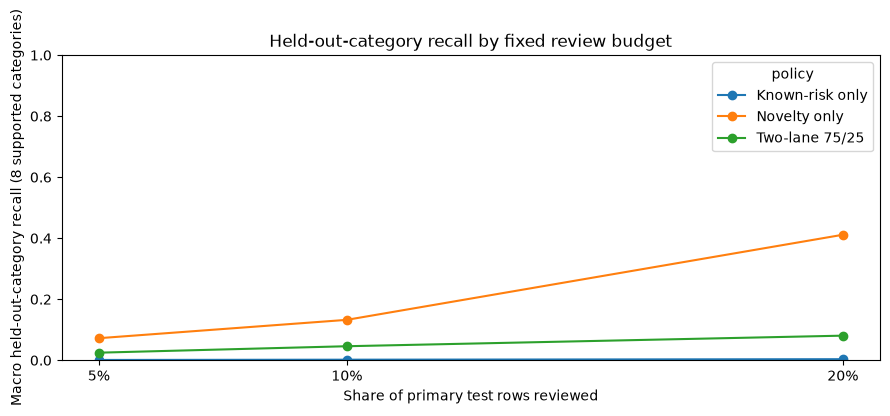

In [8]:
supported_results = results.loc[results.heldout_test_support.ge(100)]
budget_summary = supported_results.groupby(['budget_rate', 'policy']).agg(
    supported_categories=('heldout_category', 'nunique'),
    macro_heldout_category_recall=('heldout_category_recall', 'mean'),
    macro_known_category_recall=('known_category_recall', 'mean'),
    macro_precision=('precision', 'mean'),
    mean_normal_alerts_per_1000=('normal_alerts_per_1000', 'mean'),
    mean_heldout_precision_in_novelty_lane=('heldout_precision_in_novelty_lane', 'mean'),
).reset_index().sort_values(['budget_rate', 'policy'])
display(budget_summary.round(4))

ax = budget_summary.pivot(index='budget_rate', columns='policy', values='macro_heldout_category_recall').plot(
    marker='o', figsize=(9, 4), ylim=(0, 1), title='Held-out-category recall by fixed review budget')
ax.set_xlabel('Share of primary test rows reviewed')
ax.set_ylabel('Macro held-out-category recall (8 supported categories)')
ax.set_xticks(BUDGET_RATES, [f'{rate:.0%}' for rate in BUDGET_RATES])
plt.tight_layout()
plt.show()

## 9. Explain one held-out attack example

This example uses the `Exploits` fold when available. The XGBoost SHAP contributions explain the **known-risk score**. Separately, we compare the flow's numeric values with the normal training distribution to give context for its Isolation Forest novelty score. Marginal feature comparisons are not an explanation of the Isolation Forest itself and do not establish cause or attacker intent.

Held-out category: Exploits
Known-risk model score: 0.8452
Isolation Forest novelty score (higher = more unusual): 0.4596


,feature,contribution_to_margin
6,numeric__sttl,1.285234
125,categorical__service_dns,-0.539723
12,numeric__ct_srv_src,0.439195
10,numeric__sloss,0.264085
3,numeric__sbytes,-0.190021
8,numeric__sload,0.186179
0,numeric__dur,0.183319
123,categorical__service_-,-0.169857
4,numeric__dbytes,0.132184
2,numeric__dpkts,-0.116553


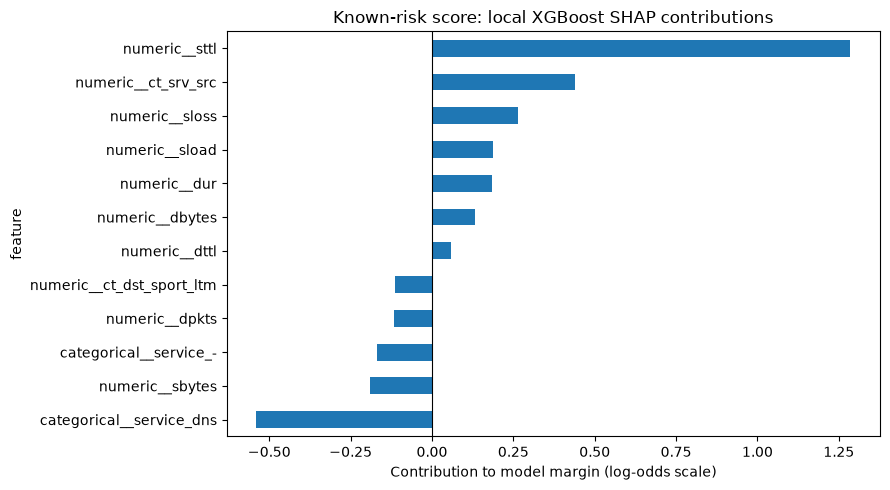

,feature,flow_value,normal_p05,normal_median,normal_p95,outside_normal_5_95_range
5,rate,1.111111e+05,0.074602,1382.256617,1.000000e+05,True
6,sload,4.622222e+07,6.134946,431327.656250,4.500000e+07,True
0,dur,9.000000e-06,0.000002,0.038602,2.388117e+00,False
1,spkts,2.000000e+00,2.000000,12.000000,1.080000e+02,False
2,dpkts,0.000000e+00,0.000000,10.000000,1.140000e+02,False
3,sbytes,1.040000e+02,78.000000,1470.000000,1.899400e+04,False
4,dbytes,0.000000e+00,0.000000,1112.000000,6.351600e+04,False
7,dload,0.000000e+00,0.000000,336120.640650,1.272609e+07,False


In [9]:
if focus_artifact is None:
    raise RuntimeError('No focus fold was retained for the explanation cell.')
focus_rows = test.loc[test.label.eq(1) & test.attack_cat.eq(focus_category)]
if focus_rows.empty:
    raise ValueError(f'No held-out {focus_category} attack rows in the primary test set.')
example = focus_rows.iloc[[0]]
focus_preprocessor = focus_artifact['preprocessor']
focus_model = focus_artifact['known_model']
X_example = focus_preprocessor.transform(example[FEATURES])
known_score = float(focus_model.predict_proba(X_example)[0, 1])
novelty_score = float(-focus_artifact['isolation_forest'].score_samples(
    np.log1p(example[ANOMALY_FEATURES]))[0])
print('Held-out category:', focus_category)
print('Known-risk model score:', round(known_score, 4))
print('Isolation Forest novelty score (higher = more unusual):', round(novelty_score, 4))

feature_names = focus_preprocessor.get_feature_names_out()
shap_values = focus_model.get_booster().predict(DMatrix(X_example), pred_contribs=True)[0][:-1]
shap_table = pd.DataFrame({'feature': feature_names, 'contribution_to_margin': shap_values})
shap_table['absolute_contribution'] = shap_table.contribution_to_margin.abs()
display(shap_table.sort_values('absolute_contribution', ascending=False).head(12).drop(columns='absolute_contribution'))

shap_top = shap_table.nlargest(12, 'absolute_contribution').sort_values('contribution_to_margin')
ax = shap_top.set_index('feature').contribution_to_margin.plot(kind='barh', figsize=(9, 5), title='Known-risk score: local XGBoost SHAP contributions')
ax.axvline(0, color='black', linewidth=0.8)
ax.set_xlabel('Contribution to model margin (log-odds scale)')
plt.tight_layout()
plt.show()

reference = focus_artifact['normal_reference']
quantiles = reference[ANOMALY_FEATURES].quantile([0.05, 0.50, 0.95])
value = example.iloc[0]
deviation_rows = []
for feature in ANOMALY_FEATURES:
    low, median, high = quantiles.loc[0.05, feature], quantiles.loc[0.50, feature], quantiles.loc[0.95, feature]
    deviation_rows.append({
        'feature': feature,
        'flow_value': float(value[feature]),
        'normal_p05': float(low),
        'normal_median': float(median),
        'normal_p95': float(high),
        'outside_normal_5_95_range': bool(value[feature] < low or value[feature] > high),
    })
display(pd.DataFrame(deviation_rows).sort_values('outside_normal_5_95_range', ascending=False))

## 10. Findings and interpretation

Read `docs/FINDINGS.md` for the saved result tables after the full notebook run. Interpret held-out-category results as **category-level generalization within UNSW-NB15**, not a demonstration of zero-day detection. Attack categories are dataset labels, traffic is synthetic and attack-heavy, exact and within-file duplicate rows remain a limitation, and there are no timestamps or analyst feedback.

The design's value is the evaluation question: known-risk ranking versus novelty routing, measured at the same review capacity. It does not claim a new detection algorithm or a production-ready operating policy.